In [1]:

!pip install -q pandas numpy matplotlib seaborn scikit-learn nltk


In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import nltk
import re
import string

from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

import warnings
warnings.filterwarnings('ignore')

print("All libraries imported successfully!")


All libraries imported successfully!


In [3]:

nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

print("NLTK resources downloaded successfully!")


[nltk_data] Downloading package punkt to C:\Users\nehma/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\nehma/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\nehma/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to C:\Users\nehma/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to C:\Users\nehma/nltk_data...


NLTK resources downloaded successfully!


[nltk_data]   Package omw-1.4 is already up-to-date!


In [4]:

# Creating the heart health dataset

data = {
    'query': [
        'What is heart disease?',
        'What causes a heart attack?',
        'How can I keep my heart healthy?',
        'Which foods are good for the heart?',
        'What are the symptoms of heart problems?'
    ],
    'intent': [
        'heart_disease',
        'heart_disease',
        'prevention',
        'diet',
        'symptoms'
    ]
}

df = pd.DataFrame(data)

print("Heart health dataset created successfully!")
print(df.head())


Heart health dataset created successfully!
                                      query         intent
0                    What is heart disease?  heart_disease
1               What causes a heart attack?  heart_disease
2          How can I keep my heart healthy?     prevention
3       Which foods are good for the heart?           diet
4  What are the symptoms of heart problems?       symptoms


In [5]:

# Creating a hierarchical taxonomy for heart health

taxonomy = {
    "Heart Conditions": [
        "Heart Disease",
        "Blood Pressure Problems"
    ],

    "Heart Symptoms": [
        "Common Symptoms",
        "Emergency Symptoms"
    ],

    "Heart Care": [
        "Disease Prevention",
        "Healthy Lifestyle"
    ],

    "Treatment and Nutrition": [
        "Heart Healthy Diet",
        "Medicines and Treatment"
    ]
}

print("Heart Health Taxonomy\n")

for category, subcategories in taxonomy.items():
    print(category)
    
    for subcategory in subcategories:
        print("  -", subcategory)
    
    print()


Heart Health Taxonomy

Heart Conditions
  - Heart Disease
  - Blood Pressure Problems

Heart Symptoms
  - Common Symptoms
  - Emergency Symptoms

Heart Care
  - Disease Prevention
  - Healthy Lifestyle

Treatment and Nutrition
  - Heart Healthy Diet
  - Medicines and Treatment



In [6]:

taxonomy_data = []

for category, subcategories in taxonomy.items():
    for subcategory in subcategories:
        taxonomy_data.append([category, subcategory])

taxonomy_df = pd.DataFrame(
    taxonomy_data,
    columns=["Main Category", "Subcategory"]
)

taxonomy_df


,Main Category,Subcategory
0,Heart Conditions,Heart Disease
1,Heart Conditions,Blood Pressure Problems
2,Heart Symptoms,Common Symptoms
3,Heart Symptoms,Emergency Symptoms
4,Heart Care,Disease Prevention
5,Heart Care,Healthy Lifestyle
6,Treatment and Nutrition,Heart Healthy Diet
7,Treatment and Nutrition,Medicines and Treatment


In [7]:

# Important concepts related to heart health

concepts = [
    "Heart",
    "Blood Pressure",
    "Cholesterol",
    "Blood Vessels",
    "Heart Disease",
    "Exercise",
    "Healthy Diet",
    "Medication",
    "Heart Attack",
    "Smoking"
]

print("Heart Health Domain Concepts:\n")

for concept in concepts:
    print("-", concept)

print("\nTotal Concepts:", len(concepts))


Heart Health Domain Concepts:

- Heart
- Blood Pressure
- Cholesterol
- Blood Vessels
- Heart Disease
- Exercise
- Healthy Diet
- Medication
- Heart Attack
- Smoking

Total Concepts: 10


In [8]:

# Relationships between different heart health concepts

relationships = [
    ("High Blood Pressure", "increases risk of", "Heart Disease"),
    ("High Cholesterol", "can contribute to", "Blocked Blood Vessels"),
    ("Exercise", "improves", "Heart Health"),
    ("Healthy Diet", "helps control", "Cholesterol"),
    ("Smoking", "increases risk of", "Heart Disease"),
    ("Medication", "helps manage", "Blood Pressure"),
    ("Heart Disease", "can lead to", "Heart Attack"),
    ("Blood Vessels", "carry blood to", "Heart"),
    ("Exercise", "helps control", "Blood Pressure"),
    ("Healthy Diet", "supports", "Heart Health"),
    ("High Blood Pressure", "can damage", "Blood Vessels"),
    ("Smoking", "damages", "Blood Vessels")
]

print("Heart Health Relationships:\n")

for relation in relationships:
    print(relation[0], relation[1], relation[2])

print("\nTotal Relationships:", len(relationships))


Heart Health Relationships:

High Blood Pressure increases risk of Heart Disease
High Cholesterol can contribute to Blocked Blood Vessels
Exercise improves Heart Health
Healthy Diet helps control Cholesterol
Smoking increases risk of Heart Disease
Medication helps manage Blood Pressure
Heart Disease can lead to Heart Attack
Blood Vessels carry blood to Heart
Exercise helps control Blood Pressure
Healthy Diet supports Heart Health
High Blood Pressure can damage Blood Vessels
Smoking damages Blood Vessels

Total Relationships: 12


In [9]:

relationship_df = pd.DataFrame(
    relationships,
    columns=["Concept 1", "Relationship", "Concept 2"]
)

relationship_df


,Concept 1,Relationship,Concept 2
0,High Blood Pressure,increases risk of,Heart Disease
1,High Cholesterol,can contribute to,Blocked Blood Vessels
2,Exercise,improves,Heart Health
3,Healthy Diet,helps control,Cholesterol
4,Smoking,increases risk of,Heart Disease
5,Medication,helps manage,Blood Pressure
6,Heart Disease,can lead to,Heart Attack
7,Blood Vessels,carry blood to,Heart
8,Exercise,helps control,Blood Pressure
9,Healthy Diet,supports,Heart Health


In [10]:

# Text preprocessing

lemmatizer = WordNetLemmatizer()
stop_words = set(stopwords.words('english'))

def preprocess_text(text):
    text = text.lower()
    
    words = word_tokenize(text)
    
    words = [
        word for word in words
        if word.isalpha() and word not in stop_words
    ]
    
    words = [
        lemmatizer.lemmatize(word)
        for word in words
    ]
    
    return " ".join(words)

print("Text preprocessing function created successfully!")


Text preprocessing function created successfully!


In [11]:

df['cleaned_query'] = df['query'].apply(preprocess_text)

print("Text preprocessing completed!\n")

df[['query', 'cleaned_query']].head(10)


Text preprocessing completed!



,query,cleaned_query
0,What is heart disease?,heart disease
1,What causes a heart attack?,cause heart attack
2,How can I keep my heart healthy?,keep heart healthy
3,Which foods are good for the heart?,food good heart
4,What are the symptoms of heart problems?,symptom heart problem


In [12]:

sample_text = "What are the Symptoms of Heart Diseases?"

print("Original Text:")
print(sample_text)

print("\nAfter Preprocessing:")
print(preprocess_text(sample_text))


Original Text:
What are the Symptoms of Heart Diseases?

After Preprocessing:
symptom heart disease


In [13]:

# Converting text into numerical features using TF-IDF

tfidf = TfidfVectorizer()

X = tfidf.fit_transform(df['cleaned_query'])

y = df['intent']

print("TF-IDF applied successfully!")
print("Number of queries:", X.shape[0])
print("Number of features:", X.shape[1])


TF-IDF applied successfully!
Number of queries: 5
Number of features: 10


In [14]:

tfidf_df = pd.DataFrame(
    X.toarray(),
    columns=tfidf.get_feature_names_out()
)

tfidf_df.head()


,attack,cause,disease,food,good,healthy,heart,keep,problem,symptom
0,0.000000,0.000000,0.90275,0.000000,0.000000,0.000000,0.430165,0.000000,0.000000,0.000000
1,0.670092,0.670092,0.00000,0.000000,0.000000,0.000000,0.319302,0.000000,0.000000,0.000000
2,0.000000,0.000000,0.00000,0.000000,0.000000,0.670092,0.319302,0.670092,0.000000,0.000000
3,0.000000,0.000000,0.00000,0.670092,0.670092,0.000000,0.319302,0.000000,0.000000,0.000000
4,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.319302,0.000000,0.670092,0.670092


In [16]:

print("Dataset shape:", df.shape)

print("\nIntent distribution:")
print(df['intent'].value_counts())

print("\nTF-IDF shape:", X.shape)

print("\nLabels shape:", y.shape)


Dataset shape: (5, 3)

Intent distribution:
intent
heart_disease    2
prevention       1
diet             1
symptoms         1
Name: count, dtype: int64

TF-IDF shape: (5, 10)

Labels shape: (5,)


In [17]:


# Splitting data into training and testing sets

y = df['intent']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training and testing data created successfully!")
print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])



Training and testing data created successfully!
Training samples: 4
Testing samples: 1


In [18]:

# Training the Naive Bayes model

model = MultinomialNB()

model.fit(X_train, y_train)

print("Model trained successfully!")


Model trained successfully!


In [19]:

# Predicting the intent of test queries

y_pred = model.predict(X_test)

print("Prediction completed successfully!")

results = pd.DataFrame({
    'Actual Intent': y_test.values,
    'Predicted Intent': y_pred
})

results


Prediction completed successfully!


,Actual Intent,Predicted Intent
0,heart_disease,heart_disease


Model Accuracy: 100.0 %
Classification Report:

               precision    recall  f1-score   support

heart_disease       1.00      1.00      1.00         1

     accuracy                           1.00         1
    macro avg       1.00      1.00      1.00         1
 weighted avg       1.00      1.00      1.00         1



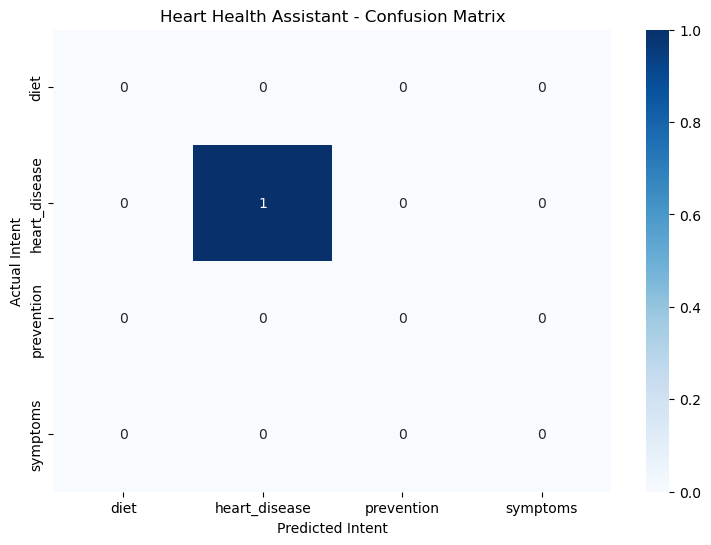

In [21]:

# Checking model accuracy

accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", round(accuracy * 100, 2), "%")

# Evaluating model performance

print("Classification Report:\n")

print(classification_report(
    y_test,
    y_pred,
    zero_division=0
))

# Creating confusion matrix

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=model.classes_
)

plt.figure(figsize=(9, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=model.classes_,
    yticklabels=model.classes_
)

plt.xlabel("Predicted Intent")
plt.ylabel("Actual Intent")
plt.title("Heart Health Assistant - Confusion Matrix")
plt.show()


In [22]:



# Creating a heart health knowledge base

knowledge_base = {
    "heart_disease": "Heart disease refers to conditions affecting the heart. Common risk factors include high blood pressure, high cholesterol, smoking and diabetes.",

    "symptoms": "Common symptoms of heart problems include chest discomfort, shortness of breath, dizziness, unusual tiredness and irregular heartbeat. These symptoms need medical evaluation.",

    "prevention": "To maintain heart health, exercise regularly, avoid smoking, maintain a healthy weight, manage blood pressure and get regular health checkups.",

    "diet": "A heart healthy diet includes fruits, vegetables, whole grains, nuts and foods low in salt and unhealthy fats.",

    "medication": "Heart medications may include blood pressure medicines, statins and blood thinners. Always follow your doctor's advice and never change medicines without consulting them.",

    "emergency": "A suspected heart attack is a medical emergency. Call emergency services immediately. In India, dial 112. Do not delay medical help."
}

print("Healthcare knowledge base created successfully!")

for topic, information in knowledge_base.items():
    print("\n", topic)
    print(information)



Healthcare knowledge base created successfully!

 heart_disease
Heart disease refers to conditions affecting the heart. Common risk factors include high blood pressure, high cholesterol, smoking and diabetes.

 symptoms
Common symptoms of heart problems include chest discomfort, shortness of breath, dizziness, unusual tiredness and irregular heartbeat. These symptoms need medical evaluation.

 prevention
To maintain heart health, exercise regularly, avoid smoking, maintain a healthy weight, manage blood pressure and get regular health checkups.

 diet
A heart healthy diet includes fruits, vegetables, whole grains, nuts and foods low in salt and unhealthy fats.

 medication
Heart medications may include blood pressure medicines, statins and blood thinners. Always follow your doctor's advice and never change medicines without consulting them.

 emergency
A suspected heart attack is a medical emergency. Call emergency services immediately. In India, dial 112. Do not delay medical help.


In [23]:

# Creating rules for the heart health assistant

emergency_words = [
    "severe chest pain",
    "chest pain and sweating",
    "heart attack",
    "not breathing",
    "unconscious",
    "collapsed",
    "severe breathing difficulty",
    "chest pressure and pain"
]

heart_keywords = [
    "heart", "cardiac", "blood pressure",
    "cholesterol", "chest", "heartbeat",
    "heart attack", "blood vessel", "diet",
    "exercise", "smoking", "medicine",
    "medication", "statin", "blood thinner",
    "breathing", "dizziness", "fainting",
    "symptom", "disease", "healthy"
]

def get_response(query):

    query_lower = query.lower()

    # Rule 1: Emergency detection
    for word in emergency_words:
        if word in query_lower:
            return "EMERGENCY: This may be a serious medical emergency. Call 112 immediately in India. Do not delay medical help."

    # Rule 2: Unsupported query
    if not any(word in query_lower for word in heart_keywords):
        return "Sorry, I can only answer questions related to heart health. Please ask a heart-related question."

    # Rule 3: Predict the intent
    cleaned_query = preprocess_text(query)
    query_vector = tfidf.transform([cleaned_query])

    prediction = model.predict(query_vector)[0]
    confidence = max(model.predict_proba(query_vector)[0])

    # Rule 4: Low confidence
    if confidence < 0.30:
        return "I am not confident enough to answer this question. Please try asking in a different way or consult a healthcare professional."

    # Rule 5: Medication safety
    if prediction == "medication":
        return knowledge_base[prediction] + " Never start, stop or change medication without consulting your doctor."

    # Rule 6: General healthcare response
    return knowledge_base[prediction]


print("All 6 reasoning rules created successfully!")


All 6 reasoning rules created successfully!


In [24]:

test_queries = [
    "What is heart disease?",
    "How can I keep my heart healthy?",
    "What foods are good for the heart?",
    "Why are blood thinners prescribed?",
    "I am having severe chest pain",
    "Tell me about computer programming"
]

for query in test_queries:
    print("\nUser:", query)
    print("Assistant:", get_response(query))
    print("-" * 60)



User: What is heart disease?
Assistant: Heart disease refers to conditions affecting the heart. Common risk factors include high blood pressure, high cholesterol, smoking and diabetes.
------------------------------------------------------------

User: How can I keep my heart healthy?
Assistant: To maintain heart health, exercise regularly, avoid smoking, maintain a healthy weight, manage blood pressure and get regular health checkups.
------------------------------------------------------------

User: What foods are good for the heart?
Assistant: A heart healthy diet includes fruits, vegetables, whole grains, nuts and foods low in salt and unhealthy fats.
------------------------------------------------------------

User: Why are blood thinners prescribed?
Assistant: I am not confident enough to answer this question. Please try asking in a different way or consult a healthcare professional.
------------------------------------------------------------

User: I am having severe chest p

In [25]:

# Creating the final heart health assistant

def heart_health_assistant():

    print("======================================")
    print("       HEART HEALTH ASSISTANT")
    print("======================================")
    print("Ask me anything about heart health.")
    print("Type 'exit' to stop the assistant.")

    while True:

        user_query = input("\nYou: ")

        if user_query.lower() == "exit":
            print("Assistant: Thank you for using Heart Health Assistant!")
            break

        response = get_response(user_query)

        print("\nAssistant:", response)


print("Heart Health Assistant is ready!")


Heart Health Assistant is ready!


In [ ]:

heart_health_assistant()


       HEART HEALTH ASSISTANT
Ask me anything about heart health.
Type 'exit' to stop the assistant.



You:  How can I keep my heart healthy?



Assistant: To maintain heart health, exercise regularly, avoid smoking, maintain a healthy weight, manage blood pressure and get regular health checkups.
